# Exploration: `slowloris.csv`

Dieses Notebook untersucht einen Angriffs-Datensatz (Flow-Features aus `flowextractor`) und evaluiert anschließend
ein `AttackDetectionNet` aus `src/flowextractor/model/model.py`, trainiert mit genau der Vorverarbeitung
(`normalize_training_data`) und dem chronologischen 80/20-Split aus `model.main()`.

Der Datensatz wird über `DATASET` in der ersten Code-Zelle gewählt (`ssh_bruteforce`, `gobuster`, `slowloris`).
`notebooks/run_all.py` führt das Notebook für alle Datensätze aus und legt je Datensatz eine eigene Kopie ab.
**Dienst-Flows** sind die Flows über den Port des angegriffenen Dienstes (SSH: 22, HTTPS: 443).

**Inhalt**
1. Überblick & Datenqualität
2. Klassenverteilung & zeitlicher Verlauf
3. Feature-Verteilungen (alle Flows und nur Dienst-Flows)
4. Ports & IP-Adressen
5. Korrelationen & normalisierte Features
6. Modelltraining
7. Evaluation (Metriken, Konfusionsmatrix, ROC/PR, Schwellwerte)
8. Robustheit: nur Dienst-Flows (inkl. Konfusionsmatrix), Port-Baseline, unbekannte Angreifer-IPs, Ablation ohne Ports
9. **Feature Importance** (Permutation Importance, Gradient × Input)
10. Fehleranalyse & Fazit


In [1]:
import os
os.environ["TQDM_DISABLE"] = "1"  # tqdm-Fortschrittsbalken aus fit() würden das Notebook aufblähen

from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from flowextractor.model.model import (
    AttackDetectionNet, normalize_training_data, print_metrics, FEATURE_COLUMNS, LOG_SCALED_COLUMNS,
)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATASET = "slowloris"  # "ssh_bruteforce" | "gobuster" | "slowloris"
DATASETS = {
    "ssh_bruteforce": {"csv": "ssh_bruteforce.csv", "port": 22, "service": "SSH"},
    "gobuster": {"csv": "gobuster.csv", "port": 443, "service": "HTTPS"},
    "slowloris": {"csv": "slowloris.csv", "port": 443, "service": "HTTPS"},
}
CSV_PATH = ROOT / DATASETS[DATASET]["csv"]
SVC_PORT = DATASETS[DATASET]["port"]   # Port des angegriffenen Dienstes
SVC = DATASETS[DATASET]["service"]

SEED = 42
EPOCHS = 20        # wie der CLI-Default von flowmodel
BATCH_SIZE = 32    # wie der CLI-Default von flowmodel
CUTOFF = 0.5

# Das Netz ist winzig: auf der CPU ist ein Thread ~8x schneller als Multi-Threading (Sync-Overhead)
torch.set_num_threads(1)

# Farben: Klasse = Identität -> feste kategoriale Slots
C_BENIGN, C_MAL, C_ALT = "#2a78d6", "#eb6834", "#1baf7a"
CLASS_COLORS = {"benign": C_BENIGN, "malicious": C_MAL}
INK, INK_MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": INK_MUTED, "axes.labelcolor": INK, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "xtick.color": INK_MUTED, "ytick.color": INK_MUTED,
    "legend.frameon": False, "lines.linewidth": 2,
})
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.width", 160)

W20261019 09:08:32.341098 140379747929856 agent.cpp:608] sysfs nodes path '/sys/class/kfd/kfd/topology/nodes' does not exist


## 1. Überblick & Datenqualität

In [2]:
raw = pd.read_csv(CSV_PATH)
raw["is_mal"] = (raw["Label"] == "malicious").astype(int)
raw["is_svc"] = (raw["Source Port"] == SVC_PORT) | (raw["Destination Port"] == SVC_PORT)
print(f"Datei: {CSV_PATH.name} ({CSV_PATH.stat().st_size / 1e6:.1f} MB)")
print(f"Flows: {len(raw):,}  |  Spalten: {raw.shape[1] - 2}")
raw.head()

Datei: slowloris.csv (69.2 MB)
Flows: 517,829  |  Spalten: 15


,Flow Hash,Source IP,Destination IP,Number of Packets,Source Port,Destination Port,Average Packet Size,Minimum Packet Size,Maximum Packet Size,Total Bytes,IAT Min,IAT Max,IAT Mean,Label,Attack Type,is_mal,is_svc
0,2727077121473071585,121.41.166.1,37.60.229.253,1,44927,35580,60.0000,60,60,60,inf,0.0000,0.0000,benign,NaN,0,False
1,1855753451732742278,37.60.229.253,121.41.166.1,1,35580,44927,54.0000,54,54,54,inf,0.0000,0.0000,benign,NaN,0,False
2,8793138229977799343,77.239.124.69,37.60.229.253,14,23264,22,166.0000,66,1202,2324,0.0000,5.0041,1.7678,benign,NaN,0,False
3,-6539293850960670423,37.60.229.253,77.239.124.69,11,22,23264,226.7273,66,1042,2494,0.0000,5.0384,2.2969,benign,NaN,0,False
4,6373266558053348005,77.239.124.69,37.60.229.253,11,23226,22,90.3636,66,150,994,0.0075,4.3983,1.8888,benign,NaN,0,False


In [3]:
num_cols = raw.select_dtypes("number").columns.drop(["is_mal", "Flow Hash"])
quality = pd.DataFrame({
    "dtype": raw[num_cols].dtypes.astype(str),
    "NaN": raw[num_cols].isna().sum(),
    "inf": np.isinf(raw[num_cols]).sum(),
    "Null-Werte": (raw[num_cols] == 0).sum(),
    "unique": raw[num_cols].nunique(),
})
quality

,dtype,NaN,inf,Null-Werte,unique
Number of Packets,int64,0,0,0,286
Source Port,int64,0,0,0,65466
Destination Port,int64,0,0,0,65474
Average Packet Size,float64,0,0,0,16526
Minimum Packet Size,int64,0,0,0,292
Maximum Packet Size,int64,0,0,0,1045
Total Bytes,int64,0,0,0,8860
IAT Min,float64,0,209294,87977,21420
IAT Max,float64,0,0,209319,304397
IAT Mean,float64,0,0,209319,307409


In [4]:
print("Label-Werte:", raw["Label"].value_counts(dropna=False).to_dict())
print("Attack Type:", raw["Attack Type"].value_counts(dropna=False).to_dict())
single = raw["Number of Packets"] == 1
print(f"\nFlows mit genau 1 Paket: {single.sum():,} ({single.mean():.1%})  -> IAT Min = inf bei {np.isinf(raw['IAT Min']).sum():,} Flows")
print(f"inf in 'IAT Min' nur bei 1-Paket-Flows: {np.isinf(raw.loc[~single, 'IAT Min']).sum() == 0}")

dup = raw["Flow Hash"].duplicated(keep=False)
conflict = raw[dup].groupby("Flow Hash")["Label"].nunique().gt(1).sum()
print(f"\nFlow-Hashes mehrfach vorhanden: {raw['Flow Hash'].duplicated().sum():,} Duplikate "
      f"({dup.sum():,} betroffene Zeilen), davon Hashes mit widersprüchlichem Label: {conflict}")
print(f"Komplett identische Feature-Zeilen (ohne Hash): {raw.drop(columns=['Flow Hash']).duplicated().sum():,}")

Label-Werte: {'benign': 415484, 'malicious': 102345}
Attack Type: {nan: 415484, 'slowloris_dos': 102345}

Flows mit genau 1 Paket: 209,294 (40.4%)  -> IAT Min = inf bei 209,294 Flows
inf in 'IAT Min' nur bei 1-Paket-Flows: True



Flow-Hashes mehrfach vorhanden: 123,957 Duplikate (189,466 betroffene Zeilen), davon Hashes mit widersprüchlichem Label: 0


Komplett identische Feature-Zeilen (ohne Hash): 903


**Hinweis:** `Attack Type` ist für benigne Flows `n/a` und wird von pandas als NaN gelesen. `IAT Min = inf` entsteht bei
Flows mit nur einem Paket; `normalize_training_data` ersetzt diese Werte durch 0.

## 2. Klassenverteilung & zeitlicher Verlauf

,Flows,Anteil
Label,,
benign,415484,80.24%
malicious,102345,19.76%


Imbalance-Verhältnis benign : malicious = 4.1 : 1


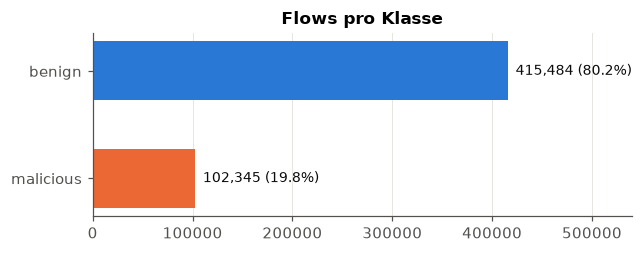

In [5]:
counts = raw["Label"].value_counts()
share = raw["Label"].value_counts(normalize=True)
display(pd.DataFrame({"Flows": counts, "Anteil": share.map("{:.2%}".format)}))
print(f"Imbalance-Verhältnis benign : malicious = {counts['benign'] / counts['malicious']:.1f} : 1")

fig, ax = plt.subplots(figsize=(6, 2.4))
ax.barh(counts.index, counts.values, color=[CLASS_COLORS[c] for c in counts.index], height=0.55)
for i, (c, v) in enumerate(counts.items()):
    ax.text(v, i, f"  {v:,} ({share[c]:.1%})", va="center", color=INK, fontsize=9)
ax.set_xlim(0, counts.max() * 1.3)
ax.set_title("Flows pro Klasse")
ax.grid(axis="y", visible=False)
ax.invert_yaxis()
plt.tight_layout()
plt.show()

Die Flows werden in Aufnahme-Reihenfolge an die CSV angehängt. Der Anteil bösartiger Flows über die Zeit zeigt, ob der
chronologische Split von `model.main()` (erste 80 % Training, letzte 20 % Test) repräsentativ ist.

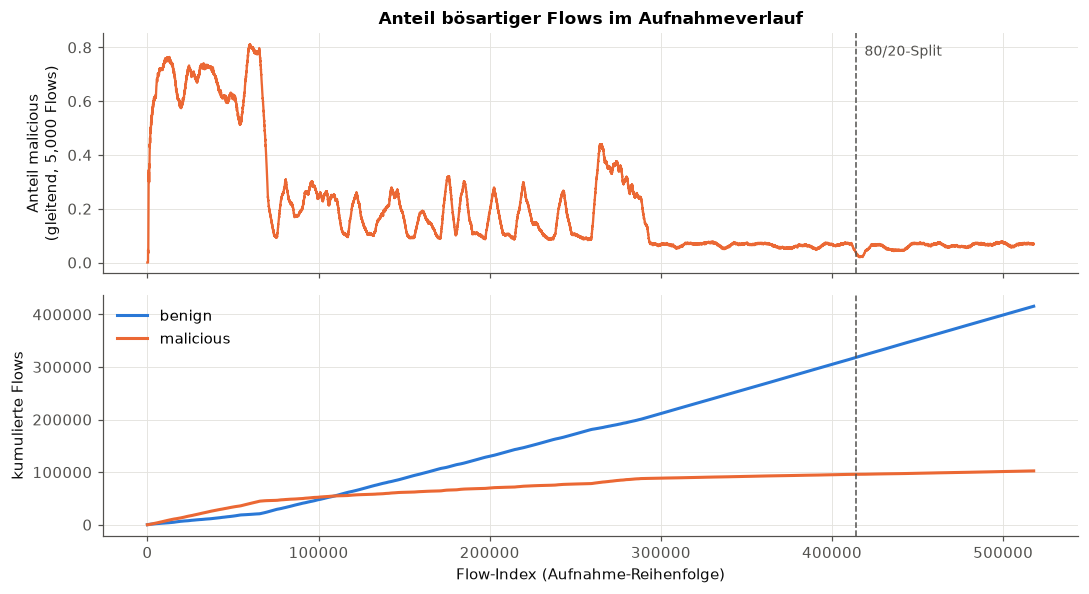

,Flows,malicious,Anteil malicious
Train (erste 80 %),414263,95835,0.2313
Test (letzte 20 %),103566,6510,0.0629


In [6]:
split_idx = int(len(raw) * 0.8)
window = 5000
rolling = raw["is_mal"].rolling(window, min_periods=1).mean()

fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
axes[0].plot(rolling.index, rolling.values, color=C_MAL, linewidth=1.5)
axes[0].set_ylabel(f"Anteil malicious\n(gleitend, {window:,} Flows)")
axes[0].set_title("Anteil bösartiger Flows im Aufnahmeverlauf")
axes[1].plot(raw.index, (1 - raw["is_mal"]).cumsum(), color=C_BENIGN, label="benign")
axes[1].plot(raw.index, raw["is_mal"].cumsum(), color=C_MAL, label="malicious")
axes[1].set_ylabel("kumulierte Flows")
axes[1].set_xlabel("Flow-Index (Aufnahme-Reihenfolge)")
axes[1].legend(loc="upper left")
for ax in axes:
    ax.axvline(split_idx, color=INK_MUTED, linestyle="--", linewidth=1)
axes[0].text(split_idx, axes[0].get_ylim()[1] * 0.95, "  80/20-Split", color=INK_MUTED, va="top", fontsize=9)
plt.tight_layout()
plt.show()

split_stats = pd.DataFrame({
    "Flows": [split_idx, len(raw) - split_idx],
    "malicious": [raw["is_mal"][:split_idx].sum(), raw["is_mal"][split_idx:].sum()],
}, index=["Train (erste 80 %)", "Test (letzte 20 %)"])
split_stats["Anteil malicious"] = split_stats["malicious"] / split_stats["Flows"]
split_stats

## 3. Feature-Verteilungen

In [7]:
feature_stats = raw.groupby("Label")[FEATURE_COLUMNS].median().T
feature_stats.columns = [f"Median {c}" for c in feature_stats.columns]
mean_stats = raw.replace(np.inf, np.nan).groupby("Label")[FEATURE_COLUMNS].mean().T
feature_stats["Mean benign"] = mean_stats["benign"]
feature_stats["Mean malicious"] = mean_stats["malicious"]
feature_stats

,Median benign,Median malicious,Mean benign,Mean malicious
Number of Packets,1.0000,17.0000,7.6919,17.1684
Source Port,"31,937.5000","25,565.0000","27,903.4337","23,700.2768"
Destination Port,"31,674.5000","32,768.0000","27,829.7683","23,700.6113"
Average Packet Size,72.0000,204.7333,242.4866,321.2288
Minimum Packet Size,66.0000,66.0000,63.0018,60.7152
Maximum Packet Size,74.0000,"1,588.0000",875.3038,"2,093.5643"
Total Bytes,120.0000,"3,932.0000","7,796.6697","5,417.5031"
IAT Min,inf,0.0000,0.0858,0.0214
IAT Max,0.0000,12.8355,0.9280,13.3237
IAT Mean,0.0000,3.9789,0.1922,4.0514


In [8]:
raw.replace(np.inf, np.nan).groupby("Label")[LOG_SCALED_COLUMNS].describe().T.unstack(level=1)

Label                     benign                                                                                     malicious                                 \
                           count       mean            std     min     25%      50%        75%                max        count       mean         std     min   
Number of Packets   415,484.0000     7.6919       805.8627  1.0000  1.0000   1.0000    10.0000       497,306.0000 102,345.0000    17.1684     33.5722  1.0000   
Average Packet Size 415,484.0000   242.4866       327.8160 54.0000 60.0000  72.0000   222.1667        13,578.1531 102,345.0000   321.2288    159.6650 54.0000   
Minimum Packet Size 415,484.0000    63.0018        24.4482 54.0000 54.0000  66.0000    66.0000         2,862.0000 102,345.0000    60.7152      5.7470 54.0000   
Maximum Packet Size 415,484.0000   875.3038     1,083.4798 54.0000 60.0000  74.0000 1,605.0000        64,442.0000 102,345.0000 2,093.5643    781.1090 54.0000   
Total Bytes         415,484.0000 7,796.6697 3,154,178.3528 54.0000 60.0000 120.0000 2,666.0000 2,030,639,951.0000 102,345.0000 5,417.5031 39,330.6635 54.0000   
IAT Min             206,193.0000     0.0858         1.5200  0.0000  0.0000   0.0000     0.0000            86.7748 102,342.0000     0.0214      0.3872  0.0000   
IAT Max             415,484.0000     0.9280         3.5616  0.0000  0.0000   0.0000     1.1740            88.5867 102,345.0000    13.3237      5.3592  0.0000   
IAT Mean            415,484.0000     0.1922         1.3079  0.0000  0.0000   0.0000     0.1459            86.7748 102,345.0000     4.0514      1.0341  0.0000   

Label                                                                 
                           25%        50%        75%             max  
Number of Packets      15.0000    17.0000    19.0000      7,365.0000  
Average Packet Size   182.5000   204.7333   463.9375      1,815.3664  
Minimum Packet Size    54.0000    66.0000    66.0000        119.0000  
Maximum Packet Size 1,464.0000 1,588.0000 2,862.0000      2,946.0000  
Total Bytes         3,249.0000 3,932.0000 7,423.0000 11,411,393.0000  
IAT Min                 0.0000     0.0000     0.0000         16.9000  
IAT Max                 9.8428    12.8355    15.7293         87.1994  
IAT Mean                3.4141     3.9789     4.5262         17.3892

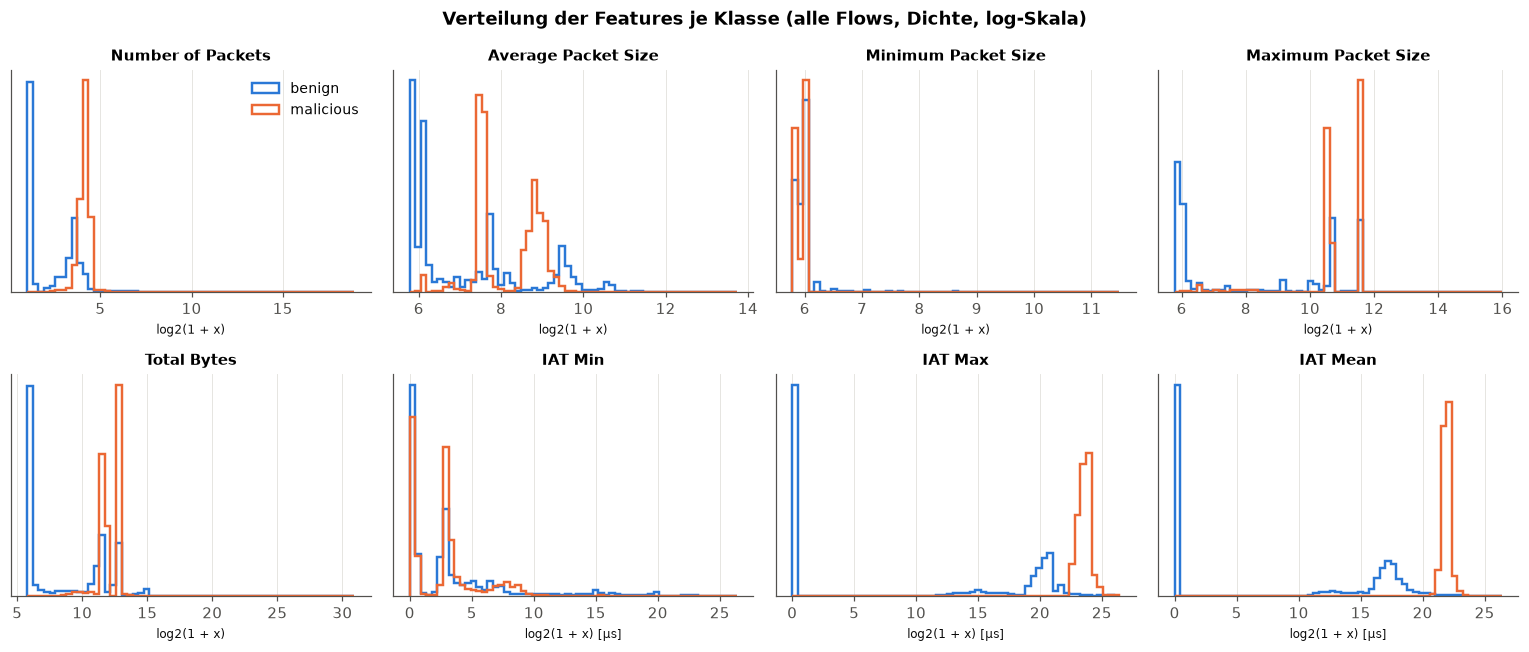

In [9]:
def class_hist(data, title, columns=LOG_SCALED_COLUMNS, bins=60):
    fig, axes = plt.subplots(2, 4, figsize=(14, 6))
    for ax, col in zip(axes.flat, columns):
        vals = data[col].replace(np.inf, np.nan)
        if col.startswith("IAT"):
            vals = vals * 1e6  # Mikrosekunden, wie in normalize_training_data
        logged = np.log2(1 + vals)
        edges = np.linspace(np.nanmin(logged), np.nanmax(logged), bins)
        for label, color in CLASS_COLORS.items():
            v = logged[data["Label"] == label].dropna()
            ax.hist(v, bins=edges, density=True, histtype="step", linewidth=1.6, color=color, label=label)
        ax.set_title(col, fontsize=10)
        ax.set_xlabel("log2(1 + x)" + (" [µs]" if col.startswith("IAT") else ""), fontsize=8)
        ax.set_yticks([])
    axes.flat[0].legend(fontsize=9)
    fig.suptitle(title, fontweight="bold")
    plt.tight_layout()
    plt.show()

class_hist(raw, "Verteilung der Features je Klasse (alle Flows, Dichte, log-Skala)")

Die Angriffe laufen (nahezu) vollständig über den Port des angegriffenen Dienstes. Die eigentlich schwierige Frage ist
daher, wie gut sich Angriffs-Flows von **legitimem Verkehr auf demselben Dienst** unterscheiden lassen. Deshalb dieselben
Verteilungen nur für die Dienst-Flows:


Anteil der malicious Flows über Port 443 (HTTPS): 99.76%


Label,benign,malicious,All
is_svc,,,
HTTPS (Port 443),171855,102096,273951
kein HTTPS,243629,249,243878
All,415484,102345,517829


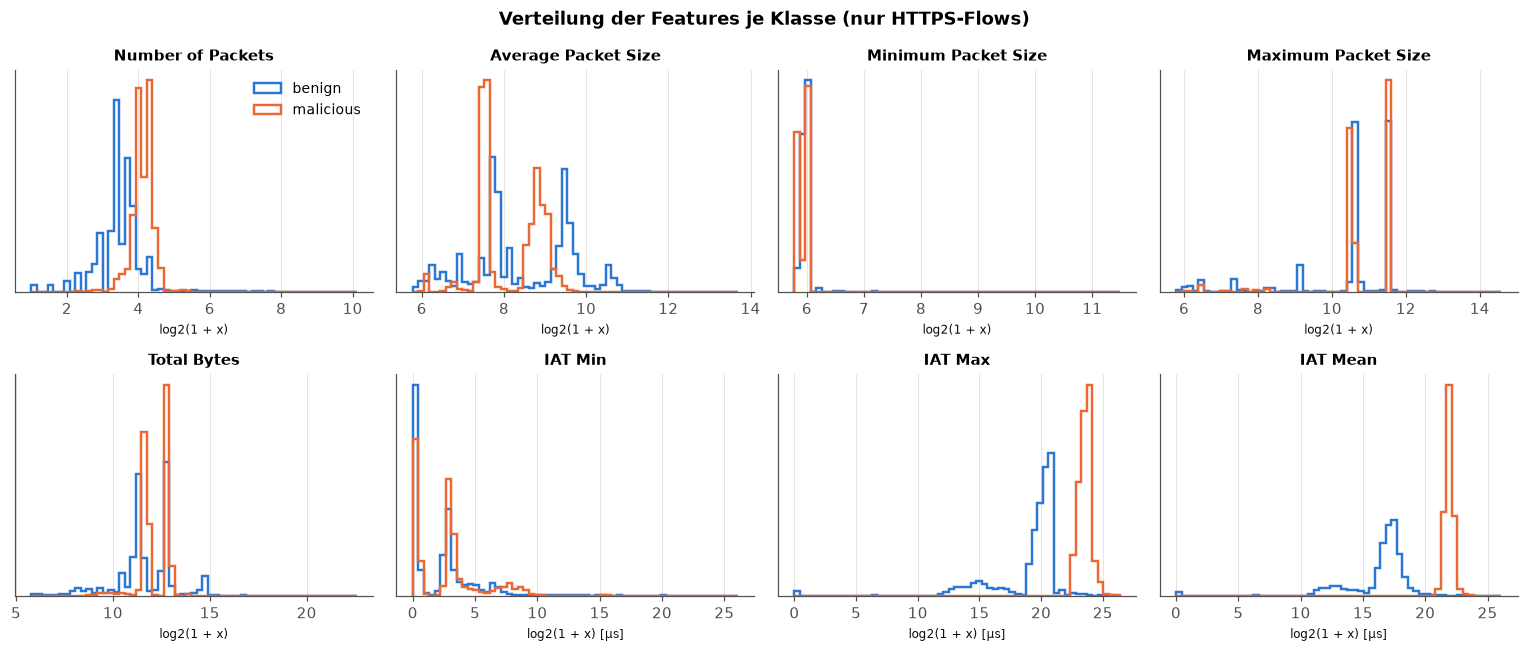

In [10]:
svc = raw[raw["is_svc"]]
print(f"Anteil der malicious Flows über Port {SVC_PORT} ({SVC}): {raw.loc[raw['is_mal'] == 1, 'is_svc'].mean():.2%}")
display(pd.crosstab(raw["is_svc"].map({True: f"{SVC} (Port {SVC_PORT})", False: f"kein {SVC}"}), raw["Label"], margins=True))
class_hist(svc, f"Verteilung der Features je Klasse (nur {SVC}-Flows)")


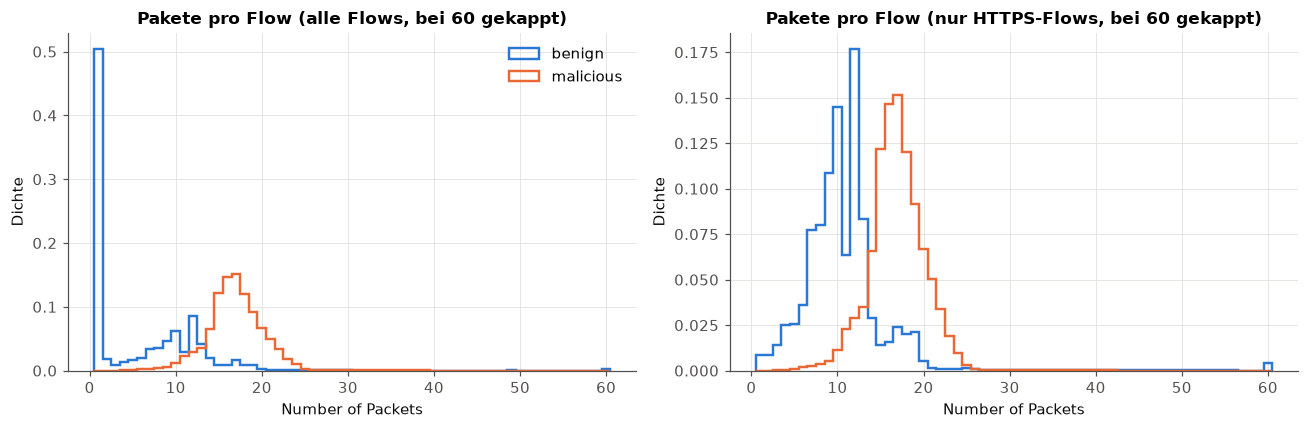

Häufigste Paketanzahlen bei malicious Flows:
{17: 0.151, 16: 0.146, 15: 0.122, 18: 0.12, 19: 0.091, 20: 0.067, 14: 0.066, 21: 0.05}


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (title, data) in zip(axes, [("alle Flows", raw), (f"nur {SVC}-Flows", svc)]):
    for label, color in CLASS_COLORS.items():
        v = data.loc[data["Label"] == label, "Number of Packets"].clip(upper=60)
        ax.hist(v, bins=np.arange(0.5, 61.5, 1), density=True, histtype="step", linewidth=1.6, color=color, label=label)
    ax.set_title(f"Pakete pro Flow ({title}, bei 60 gekappt)")
    ax.set_xlabel("Number of Packets")
    ax.set_ylabel("Dichte")
axes[0].legend()
plt.tight_layout()
plt.show()

print("Häufigste Paketanzahlen bei malicious Flows:")
print(raw.loc[raw["is_mal"] == 1, "Number of Packets"].value_counts(normalize=True).head(8).round(3).to_dict())

## 4. Ports & IP-Adressen

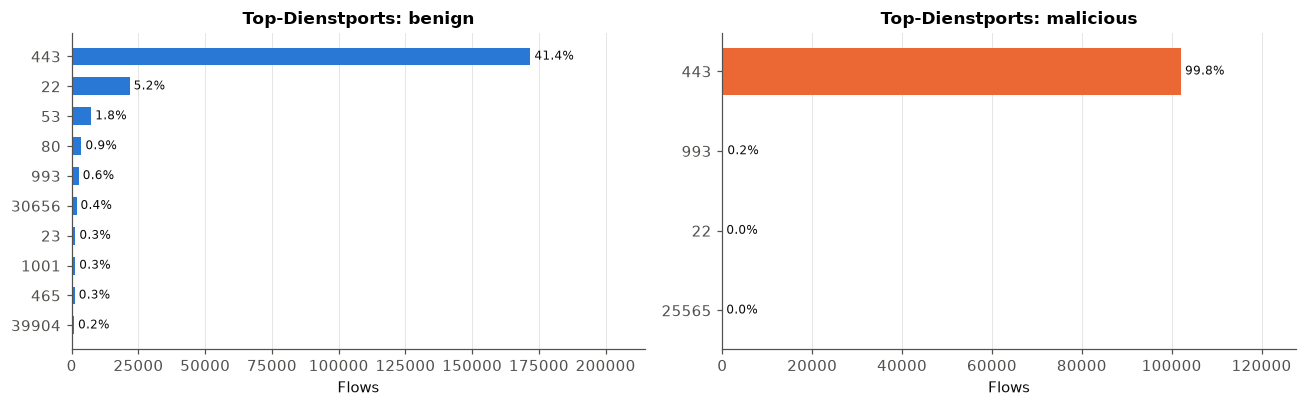

In [12]:
def top_ports(label, n=10):
    sub = raw[raw["Label"] == label]
    # "Dienst-Port" = der kleinere der beiden Ports eines Flows (Server-Seite)
    service = np.minimum(sub["Source Port"], sub["Destination Port"])
    return service.value_counts().head(n)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, label in zip(axes, ["benign", "malicious"]):
    tp = top_ports(label)
    total = (raw["Label"] == label).sum()
    ax.barh([str(p) for p in tp.index], tp.values, color=CLASS_COLORS[label], height=0.6)
    for i, v in enumerate(tp.values):
        ax.text(v, i, f" {v / total:.1%}", va="center", fontsize=8, color=INK)
    ax.invert_yaxis()
    ax.set_xlim(0, tp.max() * 1.25)
    ax.grid(axis="y", visible=False)
    ax.set_title(f"Top-Dienstports: {label}")
    ax.set_xlabel("Flows")
plt.tight_layout()
plt.show()

Überwachter Server (häufigste IP): 37.60.229.253 – in 100.0% aller Flows
Flows mit Quelle == Server: 49.9%

Unterschiedliche Angreifer-IPs: 1
Unterschiedliche Gegenstellen in benignen Flows: 6,784


Angreifer-IPs, die auch benigne Flows haben: 0
Anteil der Angriffs-Flows durch die Top-10-Angreifer: 100.0%


,count,mean,std,min,25%,50%,75%,max
Flows pro Angreifer-IP,1.0000,"102,345.0000",NaN,"102,345.0000","102,345.0000","102,345.0000","102,345.0000","102,345.0000"


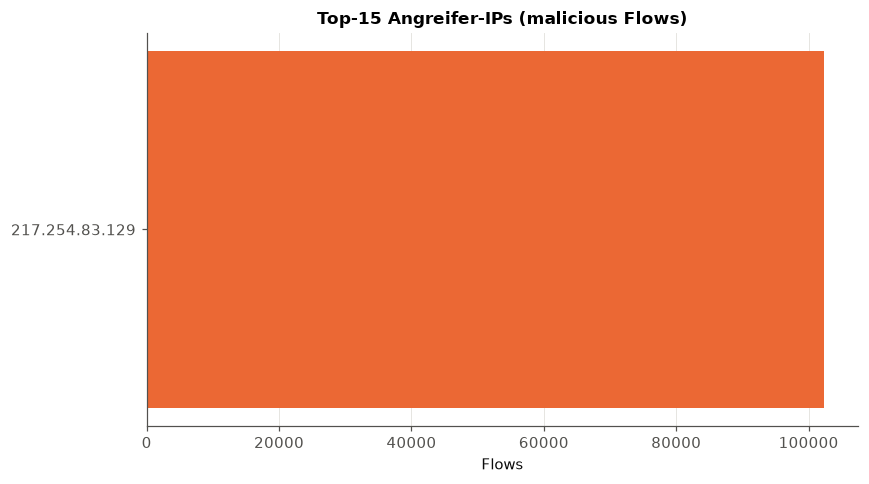

In [13]:
ip_counts = pd.concat([raw["Source IP"], raw["Destination IP"]]).value_counts()
SERVER_IP = ip_counts.index[0]
raw["peer_ip"] = np.where(raw["Source IP"] == SERVER_IP, raw["Destination IP"], raw["Source IP"])
print(f"Überwachter Server (häufigste IP): {SERVER_IP} – in {(raw['Source IP'].eq(SERVER_IP) | raw['Destination IP'].eq(SERVER_IP)).mean():.1%} aller Flows")
print(f"Flows mit Quelle == Server: {(raw['Source IP'] == SERVER_IP).mean():.1%}")

mal_peers = raw.loc[raw["is_mal"] == 1, "peer_ip"].value_counts()
ben_peers = raw.loc[raw["is_mal"] == 0, "peer_ip"]
print(f"\nUnterschiedliche Angreifer-IPs: {len(mal_peers):,}")
print(f"Unterschiedliche Gegenstellen in benignen Flows: {ben_peers.nunique():,}")
print(f"Angreifer-IPs, die auch benigne Flows haben: {len(set(mal_peers.index) & set(ben_peers)):,}")
print(f"Anteil der Angriffs-Flows durch die Top-10-Angreifer: {mal_peers.head(10).sum() / mal_peers.sum():.1%}")
display(mal_peers.describe().to_frame("Flows pro Angreifer-IP").T)

top = mal_peers.head(15)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top.index, top.values, color=C_MAL, height=0.6)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_title("Top-15 Angreifer-IPs (malicious Flows)")
ax.set_xlabel("Flows")
plt.tight_layout()
plt.show()

Angreifer-IPs im Test-Teil: 1, davon im Training nie als Angreifer gesehen: 0
Malicious Test-Flows von neuen Angreifern: 0 von 6,510


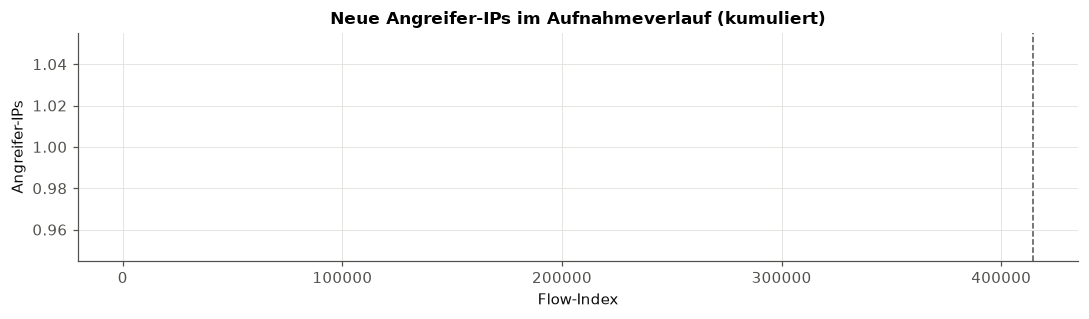

In [14]:
# Wann tauchen Angreifer zum ersten Mal auf? Relevant dafür, ob Test-Angreifer schon im Training gesehen wurden.
first_seen = raw[raw["is_mal"] == 1].groupby("peer_ip").apply(lambda g: g.index.min(), include_groups=False)
test_mal = raw.loc[split_idx:][raw.loc[split_idx:, "is_mal"] == 1]
unseen_attackers = set(first_seen[first_seen >= split_idx].index)
print(f"Angreifer-IPs im Test-Teil: {test_mal['peer_ip'].nunique():,}, davon im Training nie als Angreifer gesehen: {len(unseen_attackers):,}")
print(f"Malicious Test-Flows von neuen Angreifern: {test_mal['peer_ip'].isin(unseen_attackers).sum():,} von {len(test_mal):,}")

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(np.sort(first_seen.values), np.arange(1, len(first_seen) + 1), color=C_MAL)
ax.axvline(split_idx, color=INK_MUTED, linestyle="--", linewidth=1)
ax.set_title("Neue Angreifer-IPs im Aufnahmeverlauf (kumuliert)")
ax.set_xlabel("Flow-Index")
ax.set_ylabel("Angreifer-IPs")
plt.tight_layout()
plt.show()

## 5. Korrelationen & normalisierte Features

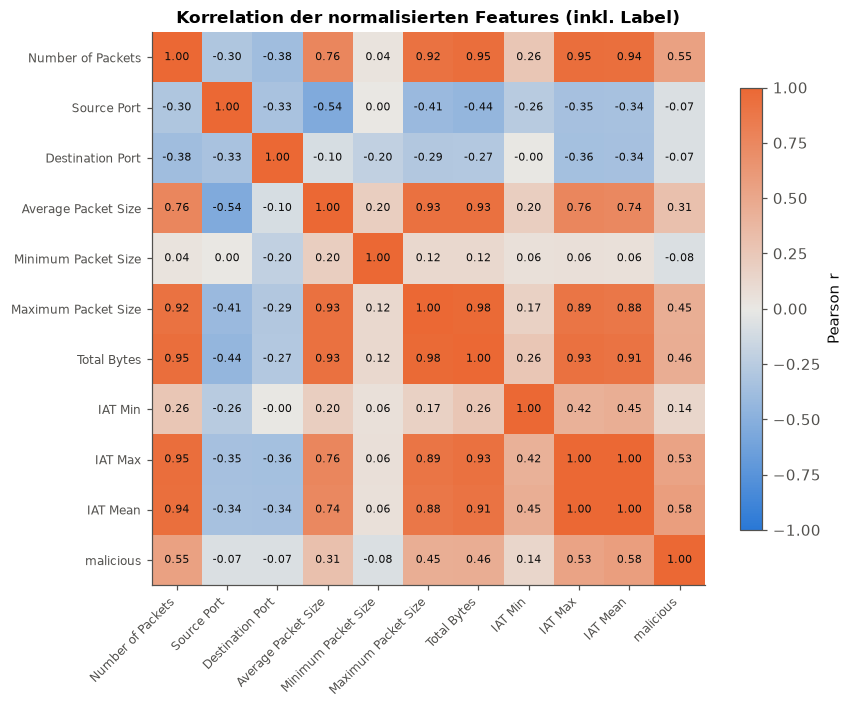

,r mit Label
IAT Mean,0.5754
Number of Packets,0.5476
IAT Max,0.5326
Total Bytes,0.4583
Maximum Packet Size,0.4510
Average Packet Size,0.3051
IAT Min,0.1380
Minimum Packet Size,-0.0767
Source Port,-0.0738
Destination Port,-0.0725


In [15]:
norm = normalize_training_data(raw)
corr = norm[FEATURE_COLUMNS].assign(malicious=raw["is_mal"]).corr()

diverging = LinearSegmentedColormap.from_list("div", [C_BENIGN, "#e9e8e4", C_MAL])
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap=diverging, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(corr)), corr.index, fontsize=8)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7, color=INK)
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson r")
ax.set_title("Korrelation der normalisierten Features (inkl. Label)")
plt.tight_layout()
plt.show()

corr["malicious"].drop("malicious").sort_values(key=abs, ascending=False).to_frame("r mit Label")

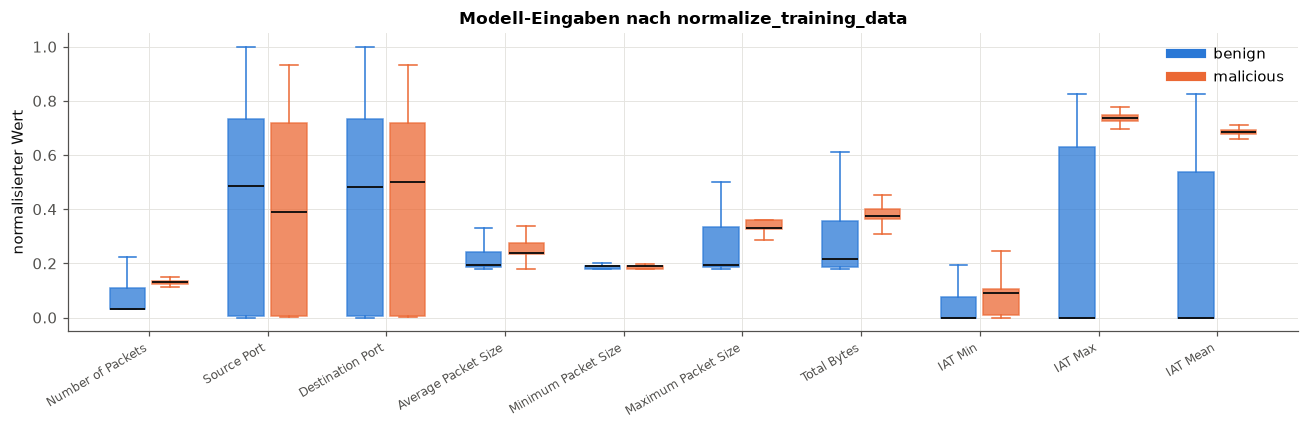

,min,max,mean,std
Number of Packets,0.0312,0.5914,0.0809,0.0439
Source Port,0.0000,1.0000,0.4131,0.3459
Destination Port,0.0000,1.0000,0.4122,0.3459
Average Packet Size,0.1807,0.4290,0.2274,0.0439
Minimum Packet Size,0.1807,0.3589,0.1866,0.0060
Maximum Packet Size,0.1807,0.4992,0.2692,0.0770
Total Bytes,0.1807,0.9662,0.2930,0.0952
IAT Min,0.0000,0.8241,0.0581,0.1086
IAT Max,0.0000,0.8250,0.3866,0.3260
IAT Mean,0.0000,0.8241,0.3446,0.2930


In [16]:
fig, ax = plt.subplots(figsize=(12, 4))
positions = np.arange(len(FEATURE_COLUMNS))
for offset, (label, color) in zip([-0.18, 0.18], CLASS_COLORS.items()):
    data = [norm.loc[norm["Label"] == label, c].values for c in FEATURE_COLUMNS]
    bp = ax.boxplot(data, positions=positions + offset, widths=0.3, showfliers=False, patch_artist=True,
                    medianprops=dict(color=INK, linewidth=1.2), whiskerprops=dict(color=color),
                    capprops=dict(color=color), boxprops=dict(facecolor=color, edgecolor=color, alpha=0.75))
    ax.plot([], [], color=color, linewidth=6, label=label)
ax.set_xticks(positions, FEATURE_COLUMNS, rotation=30, ha="right", fontsize=8)
ax.set_ylabel("normalisierter Wert")
ax.set_title("Modell-Eingaben nach normalize_training_data")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

norm[FEATURE_COLUMNS].describe().T[["min", "max", "mean", "std"]]

## 6. Modelltraining

Wie in `model.main()`: Features normalisieren, chronologisch 80/20 splitten, `AttackDetectionNet().fit(...)`.
Einzige Abweichung: fester Seed (`SEED`) für Reproduzierbarkeit; das Modell wird nicht gespeichert.

In [17]:
x = torch.tensor(norm[FEATURE_COLUMNS].to_numpy(), dtype=torch.float32)
y = torch.tensor(raw["is_mal"].to_numpy(), dtype=torch.float32)
X_train, X_test = x[:split_idx], x[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]
test_df = raw.iloc[split_idx:].reset_index(drop=True)
print(f"Train: {len(y_train):,} Flows ({int(y_train.sum()):,} malicious) | Test: {len(y_test):,} Flows ({int(y_test.sum()):,} malicious)")

torch.manual_seed(SEED)
model = AttackDetectionNet()
print(model)
print(f"Parameter: {sum(p.numel() for p in model.parameters()):,}")

Train: 414,263 Flows (95,835 malicious) | Test: 103,566 Flows (6,510 malicious)
AttackDetectionNet(
  (layers): Sequential(
    (0): Linear(in_features=10, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=8, bias=True)
    (5): ReLU()
    (6): Linear(in_features=8, out_features=1, bias=True)
  )
)
Parameter: 593


In [18]:
%%time
model.fit(list(zip(X_train, y_train)), epochs=EPOCHS, batch_size=BATCH_SIZE)

Training on cpu.


Epoch 1/20 completed. average loss: 0.04591460056333382


Epoch 2/20 completed. average loss: 0.020188175921428037


Epoch 3/20 completed. average loss: 0.0174984237450667


Epoch 4/20 completed. average loss: 0.015828742308710658


...

Epoch 17/20 completed. average loss: 0.009999459472175738


Epoch 18/20 completed. average loss: 0.009819173482941044


Epoch 19/20 completed. average loss: 0.009619806760239002


Epoch 20/20 completed. average loss: 0.00906116169985855
Training finished.


CPU times: user 9min 22s, sys: 3.33 s, total: 9min 25s
Wall time: 9min 54s


## 7. Evaluation auf dem Test-Split

In [19]:
def predict_scores(m, X):
    with torch.no_grad():
        return torch.sigmoid(m(X).squeeze(1)).numpy()


def roc_pr(y_true, scores):
    order = np.argsort(-scores, kind="mergesort")
    s, t = scores[order], y_true[order]
    distinct = np.r_[np.where(np.diff(s))[0], len(s) - 1]
    tp = np.cumsum(t)[distinct]
    fp = (distinct + 1) - tp
    P, N = t.sum(), len(t) - t.sum()
    tpr = np.r_[0, tp / P]
    fpr = np.r_[0, fp / N]
    precision = np.r_[1, tp / (tp + fp)]
    roc_auc = np.trapezoid(tpr, fpr)
    ap = np.sum(np.diff(tpr) * precision[1:])  # Average Precision
    return fpr, tpr, precision, roc_auc, ap


def metrics(y_true, y_pred, scores=None):
    y_true, y_pred = np.asarray(y_true).astype(int), np.asarray(y_pred).astype(int)
    tp = int(((y_true == 1) & (y_pred == 1)).sum()); fp = int(((y_true == 0) & (y_pred == 1)).sum())
    tn = int(((y_true == 0) & (y_pred == 0)).sum()); fn = int(((y_true == 1) & (y_pred == 0)).sum())
    prec = tp / (tp + fp) if tp + fp else np.nan
    rec = tp / (tp + fn) if tp + fn else np.nan
    spec = tn / (tn + fp) if tn + fp else np.nan
    denom = np.sqrt(float(tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    out = {
        "Flows": len(y_true), "TP": tp, "FP": fp, "TN": tn, "FN": fn,
        "Accuracy": (tp + tn) / len(y_true), "Precision": prec, "Recall": rec, "Specificity": spec,
        "F1": 2 * prec * rec / (prec + rec) if prec and rec else np.nan,
        "Balanced Acc.": (rec + spec) / 2, "MCC": (tp * tn - fp * fn) / denom if denom else np.nan,
        "FPR": fp / (fp + tn) if fp + tn else np.nan,
    }
    if scores is not None and 0 < y_true.sum() < len(y_true):
        _, _, _, auc, ap = roc_pr(y_true, scores)
        out["ROC-AUC"], out["PR-AUC (AP)"] = auc, ap
    return out


INT_COLS = ["Flows", "TP", "FP", "TN", "FN"]

def show(res):
    return pd.DataFrame(res).T.astype({c: int for c in INT_COLS})


y_true = y_test.int().numpy()
scores = predict_scores(model, X_test)
y_pred = (scores >= CUTOFF).astype(int)

# Ausgabe im Format von model.main()
print_metrics("All flows", torch.tensor(y_true), torch.tensor(y_pred))

-> All flows (103566 samples)
TP: 6509 (6.28 %), FP: 73 (0.07 %), TN: 96983 (93.64 %), FN: 1 (0.00 %)
Precision: 98.89 %
Recall: 99.98 %
F1 Score: 99.43 %


In [20]:
results = {"Modell – alle Test-Flows": metrics(y_true, y_pred, scores)}
show(results)

,Flows,TP,FP,TN,FN,Accuracy,Precision,Recall,Specificity,F1,Balanced Acc.,MCC,FPR,ROC-AUC,PR-AUC (AP)
Modell – alle Test-Flows,103566,6509,73,96983,1,0.9993,0.9889,0.9998,0.9992,0.9943,0.9995,0.9940,0.0008,1.0000,0.9999


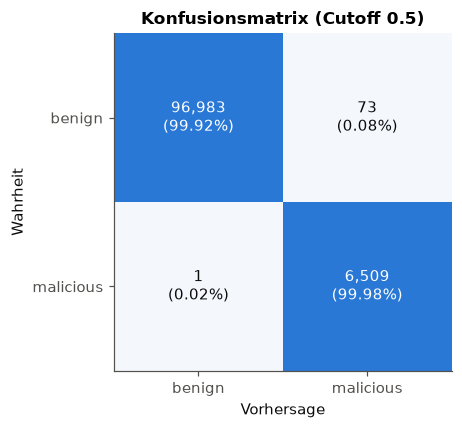

In [21]:
blues = LinearSegmentedColormap.from_list("seq", ["#f4f8fd", C_BENIGN])


def plot_confusion(m, title):
    cm = np.array([[m["TN"], m["FP"]], [m["FN"], m["TP"]]])
    cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(4.8, 4))
    ax.imshow(cm_norm, cmap=blues, vmin=0, vmax=1)
    ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n({cm_norm[i, j]:.2%})", ha="center", va="center",
                    color="white" if cm_norm[i, j] > 0.6 else INK, fontsize=10)
    ax.set_xticks([0, 1], ["benign", "malicious"])
    ax.set_yticks([0, 1], ["benign", "malicious"])
    ax.set_xlabel("Vorhersage")
    ax.set_ylabel("Wahrheit")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()


plot_confusion(results["Modell – alle Test-Flows"], f"Konfusionsmatrix (Cutoff {CUTOFF})")


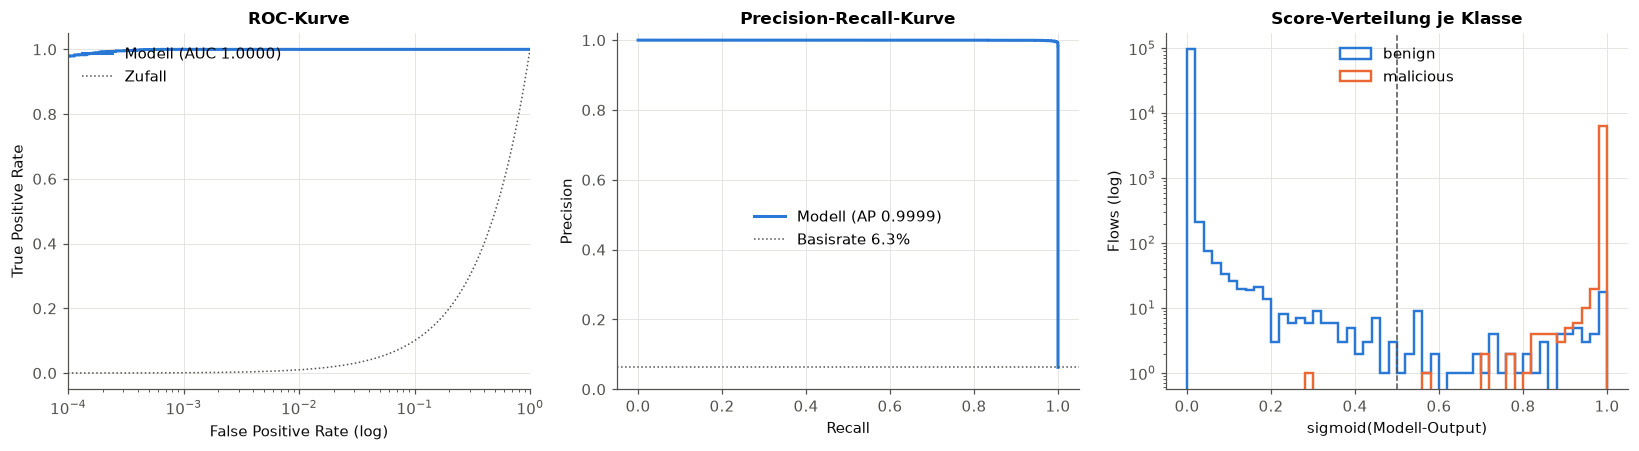

In [22]:
fpr, tpr, precision, auc, ap = roc_pr(y_true, scores)
base_rate = y_true.mean()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
axes[0].plot(fpr, tpr, color=C_BENIGN, label=f"Modell (AUC {auc:.4f})")
diag = np.logspace(-5, 0, 200)
axes[0].plot(diag, diag, color=INK_MUTED, linestyle=":", linewidth=1, label="Zufall")
axes[0].set_xscale("log")
axes[0].set_xlim(1e-4, 1)
axes[0].set_xlabel("False Positive Rate (log)")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC-Kurve")
axes[0].legend(loc="upper left")

axes[1].plot(tpr, precision, color=C_BENIGN, label=f"Modell (AP {ap:.4f})")
axes[1].axhline(base_rate, color=INK_MUTED, linestyle=":", linewidth=1, label=f"Basisrate {base_rate:.1%}")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_ylim(0, 1.02)
axes[1].set_title("Precision-Recall-Kurve")
axes[1].legend(loc="center", bbox_to_anchor=(0.5, 0.45))

edges = np.linspace(0, 1, 51)
for label, color, cls in [("benign", C_BENIGN, 0), ("malicious", C_MAL, 1)]:
    axes[2].hist(scores[y_true == cls], bins=edges, color=color, histtype="step", linewidth=1.6, label=label)
axes[2].axvline(CUTOFF, color=INK_MUTED, linestyle="--", linewidth=1)
axes[2].set_yscale("log")
axes[2].set_xlabel("sigmoid(Modell-Output)")
axes[2].set_ylabel("Flows (log)")
axes[2].set_title("Score-Verteilung je Klasse")
axes[2].legend(loc="upper center")
plt.tight_layout()
plt.show()

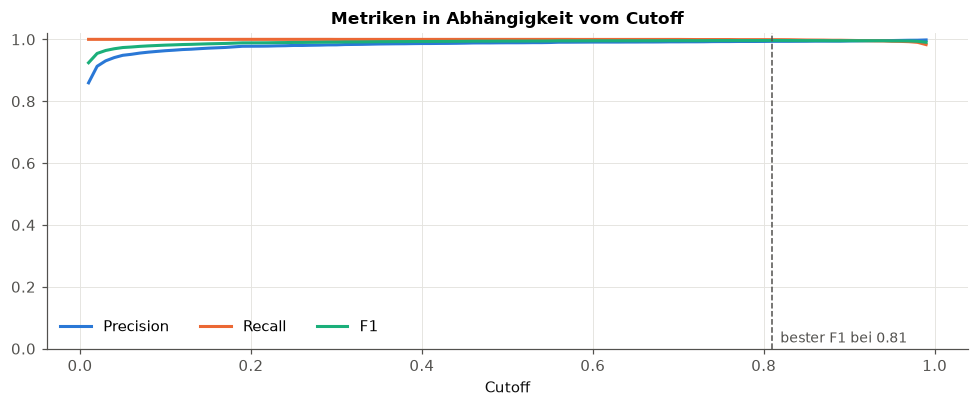

,TP,FP,FN,Precision,Recall,F1,FPR
Cutoff,,,,,,,
0.1000,6510,248,0,0.9633,1.0000,0.9813,0.0026
0.3000,6509,118,1,0.9822,0.9998,0.9909,0.0012
0.5000,6509,73,1,0.9889,0.9998,0.9943,0.0008
0.7000,6508,53,2,0.9919,0.9997,0.9958,0.0005
0.9000,6488,34,22,0.9948,0.9966,0.9957,0.0004
0.8100,6503,42,7,0.9936,0.9989,0.9962,0.0004


In [23]:
thresholds = np.round(np.linspace(0.01, 0.99, 99), 2)
sweep = pd.DataFrame([{"Cutoff": t, **metrics(y_true, (scores >= t).astype(int))} for t in thresholds]).set_index("Cutoff")

fig, ax = plt.subplots(figsize=(9, 3.8))
for col, color in [("Precision", C_BENIGN), ("Recall", C_MAL), ("F1", C_ALT)]:
    ax.plot(sweep.index, sweep[col], color=color, label=col)
best = sweep["F1"].idxmax()
ax.axvline(best, color=INK_MUTED, linestyle="--", linewidth=1)
ax.text(best, 0.02, f"  bester F1 bei {best:.2f}", color=INK_MUTED, fontsize=9)
ax.set_xlabel("Cutoff")
ax.set_ylim(0, 1.02)
ax.set_title("Metriken in Abhängigkeit vom Cutoff")
ax.legend(loc="lower left", ncol=3)
plt.tight_layout()
plt.show()

sweep.loc[[0.1, 0.3, CUTOFF, 0.7, 0.9, round(best, 2)], ["TP", "FP", "FN", "Precision", "Recall", "F1", "FPR"]].drop_duplicates()

## 8. Robustheit

Da (nahezu) sämtliche Angriffe über den Dienst-Port laufen und die Ports Teil der Features sind, könnte das Modell im
Wesentlichen „Dienst-Port → malicious“ gelernt haben. Prüfungen:

* **Nur Dienst-Flows**: die eigentlich schwierige Teilmenge (Angriff vs. legitimer Verkehr auf demselben Dienst)
* **Baseline**: Regel „Dienst-Port ⇒ malicious“ ohne Modell
* **Unbekannte Angreifer**: malicious Test-Flows von IPs, die im Training nie als Angreifer vorkamen
* **Ablation**: dasselbe Netz, trainiert mit auf 0 gesetzten Port-Features


In [24]:
svc_mask = test_df["is_svc"].to_numpy()
results[f"Modell – nur {SVC}-Flows"] = metrics(y_true[svc_mask], y_pred[svc_mask], scores[svc_mask])
results[f"Baseline Port {SVC_PORT} – alle Flows"] = metrics(y_true, svc_mask.astype(int))

show(results)


,Flows,TP,FP,TN,FN,Accuracy,Precision,Recall,Specificity,F1,Balanced Acc.,MCC,FPR,ROC-AUC,PR-AUC (AP)
Modell – alle Test-Flows,103566,6509,73,96983,1,0.9993,0.9889,0.9998,0.9992,0.9943,0.9995,0.9940,0.0008,1.0000,0.9999
Modell – nur HTTPS-Flows,79204,6509,4,72690,1,0.9999,0.9994,0.9998,0.9999,0.9996,0.9999,0.9996,0.0001,1.0000,1.0000
Baseline Port 443 – alle Flows,103566,6510,72694,24362,0,0.2981,0.0822,1.0000,0.2510,0.1519,0.6255,0.1436,0.7490,NaN,NaN


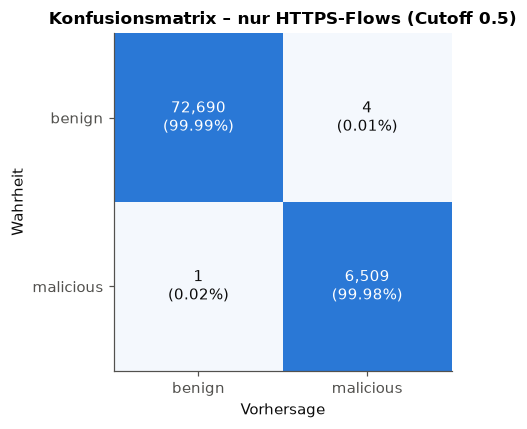

In [25]:
plot_confusion(results[f"Modell – nur {SVC}-Flows"], f"Konfusionsmatrix – nur {SVC}-Flows (Cutoff {CUTOFF})")


Erkennungsrate (Recall) für Angreifer, deren IP im Trainingsteil nie als Angreifer auftauchte, im Vergleich zu bereits
bekannten Angreifer-IPs. Precision ist hier nicht sinnvoll vergleichbar, da beide Gruppen dieselben benignen Flows teilen.

In [26]:
new_att = test_df["peer_ip"].isin(unseen_attackers).to_numpy()
by_group = []
for name, mask in [("neue Angreifer-IPs", new_att), ("bekannte Angreifer-IPs", ~new_att)]:
    sel = (y_true == 1) & mask
    by_group.append({"Gruppe": name, "IPs": test_df.loc[sel, "peer_ip"].nunique(), "malicious Flows": int(sel.sum()),
                     "erkannt": int(y_pred[sel].sum()), "Recall": y_pred[sel].mean() if sel.any() else np.nan,
                     "Median-Score": np.median(scores[sel]) if sel.any() else np.nan})
pd.DataFrame(by_group).set_index("Gruppe")

,IPs,malicious Flows,erkannt,Recall,Median-Score
Gruppe,,,,,
neue Angreifer-IPs,0,0,0,NaN,NaN
bekannte Angreifer-IPs,1,6510,6509,0.9998,0.9998


In [27]:
%%time
PORT_IDX = [FEATURE_COLUMNS.index("Source Port"), FEATURE_COLUMNS.index("Destination Port")]
x_np = x.clone()
x_np[:, PORT_IDX] = 0
X_train_np, X_test_np = x_np[:split_idx], x_np[split_idx:]

torch.manual_seed(SEED)
model_noport = AttackDetectionNet()
model_noport.fit(list(zip(X_train_np, y_train)), epochs=EPOCHS, batch_size=BATCH_SIZE)

Training on cpu.


Epoch 1/20 completed. average loss: 0.049431122120325896


Epoch 2/20 completed. average loss: 0.024469276850290947


Epoch 3/20 completed. average loss: 0.021904070942739846


Epoch 4/20 completed. average loss: 0.020702253859128123


...

Epoch 17/20 completed. average loss: 0.012611661762486712


Epoch 18/20 completed. average loss: 0.012234424418765951


Epoch 19/20 completed. average loss: 0.012150006336703245


Epoch 20/20 completed. average loss: 0.01192624526070274
Training finished.


CPU times: user 8min 49s, sys: 1.75 s, total: 8min 50s
Wall time: 9min 4s


In [28]:
scores_np = predict_scores(model_noport, X_test_np)
y_pred_np = (scores_np >= CUTOFF).astype(int)
results["Ablation ohne Ports – alle Flows"] = metrics(y_true, y_pred_np, scores_np)
results[f"Ablation ohne Ports – nur {SVC}-Flows"] = metrics(y_true[svc_mask], y_pred_np[svc_mask], scores_np[svc_mask])

summary = show(results)
summary[["Flows", "TP", "FP", "FN", "Precision", "Recall", "F1", "MCC", "FPR", "ROC-AUC", "PR-AUC (AP)"]]

,Flows,TP,FP,FN,Precision,Recall,F1,MCC,FPR,ROC-AUC,PR-AUC (AP)
Modell – alle Test-Flows,103566,6509,73,1,0.9889,0.9998,0.9943,0.9940,0.0008,1.0000,0.9999
Modell – nur HTTPS-Flows,79204,6509,4,1,0.9994,0.9998,0.9996,0.9996,0.0001,1.0000,1.0000
Baseline Port 443 – alle Flows,103566,6510,72694,0,0.0822,1.0000,0.1519,0.1436,0.7490,NaN,NaN
Ablation ohne Ports – alle Flows,103566,6508,124,2,0.9813,0.9997,0.9904,0.9898,0.0013,1.0000,0.9996
Ablation ohne Ports – nur HTTPS-Flows,79204,6508,18,2,0.9972,0.9997,0.9985,0.9983,0.0002,1.0000,1.0000


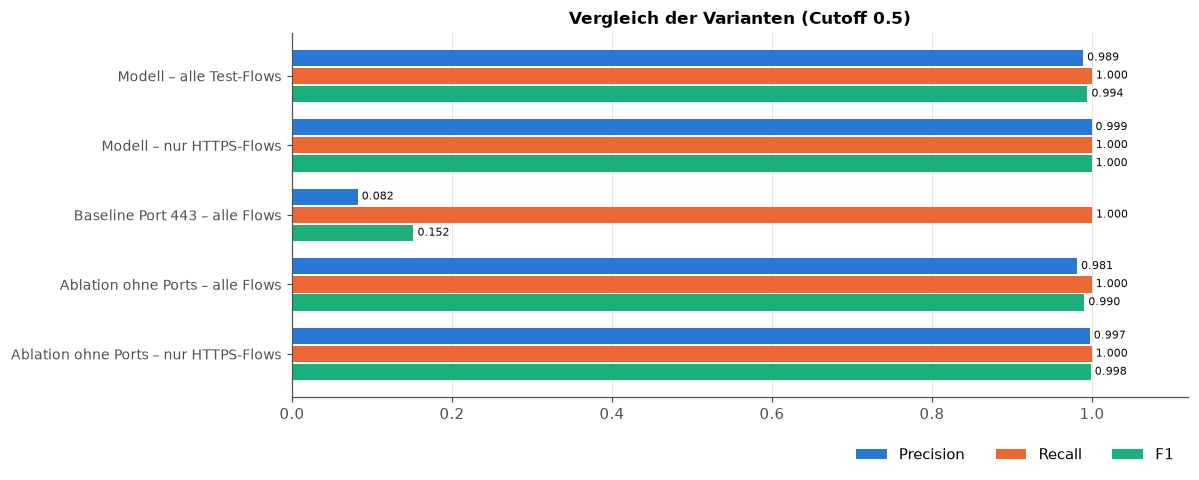

In [29]:
plot_rows = ["Modell – alle Test-Flows", f"Modell – nur {SVC}-Flows", f"Baseline Port {SVC_PORT} – alle Flows",
             "Ablation ohne Ports – alle Flows", f"Ablation ohne Ports – nur {SVC}-Flows"]
plot_metrics = [("Precision", C_BENIGN), ("Recall", C_MAL), ("F1", C_ALT)]
fig, ax = plt.subplots(figsize=(11, 4.5))
ypos = np.arange(len(plot_rows))
h = 0.26
for k, (metric, color) in enumerate(plot_metrics):
    vals = summary.loc[plot_rows, metric].astype(float).values
    ax.barh(ypos + (k - 1) * h, vals, height=h * 0.9, color=color, label=metric)
    for yy, v in zip(ypos + (k - 1) * h, vals):
        ax.text(v, yy, f" {v:.3f}", va="center", fontsize=7, color=INK)
ax.set_yticks(ypos, plot_rows, fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, 1.12)
ax.grid(axis="y", visible=False)
ax.set_title(f"Vergleich der Varianten (Cutoff {CUTOFF})")
ax.legend(loc="lower right", ncol=3, bbox_to_anchor=(1, -0.22))
plt.tight_layout()
plt.show()

## 9. Feature Importance

**Permutation Importance:** Für jedes Feature werden dessen Werte im Test-Set zufällig permutiert (übrige Features
unverändert) und der Score neu berechnet. Der Abfall des F1-Scores (Cutoff 0.5) gegenüber den unveränderten Daten
misst, wie stark sich das Modell auf dieses Feature verlässt. Jeweils `N_REPEATS` Permutationen; Fehlerbalken = Standardabweichung.

Ausgewertet für das Modell auf allen Test-Flows und nur auf Dienst-Flows sowie für das Ablationsmodell ohne Ports (nur Dienst-Flows).

In [30]:
N_REPEATS = 10


def permutation_importance(m, X, y_true, n_repeats=N_REPEATS, seed=SEED):
    rng = np.random.default_rng(seed)
    base_f1 = metrics(y_true, (predict_scores(m, X) >= CUTOFF).astype(int))["F1"]
    rows = []
    for j, col in enumerate(FEATURE_COLUMNS):
        d_f1 = []
        for _ in range(n_repeats):
            Xp = X.clone()
            Xp[:, j] = Xp[torch.from_numpy(rng.permutation(len(Xp))), j]
            s = predict_scores(m, Xp)
            d_f1.append(base_f1 - metrics(y_true, (s >= CUTOFF).astype(int))["F1"])
        rows.append({"Feature": col, "Δ F1": np.mean(d_f1), "Δ F1 std": np.std(d_f1)})
    return pd.DataFrame(rows).set_index("Feature")


svc_t = torch.tensor(svc_mask)
importance = {
    "Modell – alle Test-Flows": permutation_importance(model, X_test, y_true),
    f"Modell – nur {SVC}-Flows": permutation_importance(model, X_test[svc_t], y_true[svc_mask]),
    f"Ablation ohne Ports – nur {SVC}-Flows": permutation_importance(model_noport, X_test_np[svc_t], y_true[svc_mask]),
}
pd.concat({k: v["Δ F1"] for k, v in importance.items()}, axis=1).sort_values(
    "Modell – alle Test-Flows", ascending=False)

,Modell – alle Test-Flows,Modell – nur HTTPS-Flows,Ablation ohne Ports – nur HTTPS-Flows
Feature,,,
IAT Mean,0.8930,0.8911,0.9031
Destination Port,0.2464,0.2619,0.0000
Source Port,0.2196,0.2407,0.0000
IAT Max,0.1631,0.0551,0.0763
IAT Min,0.1542,0.1193,0.0027
Total Bytes,0.1187,0.0058,0.0114
Number of Packets,0.0741,0.0033,0.0285
Maximum Packet Size,0.0560,0.0103,0.0279
Average Packet Size,0.0037,0.0006,0.0018


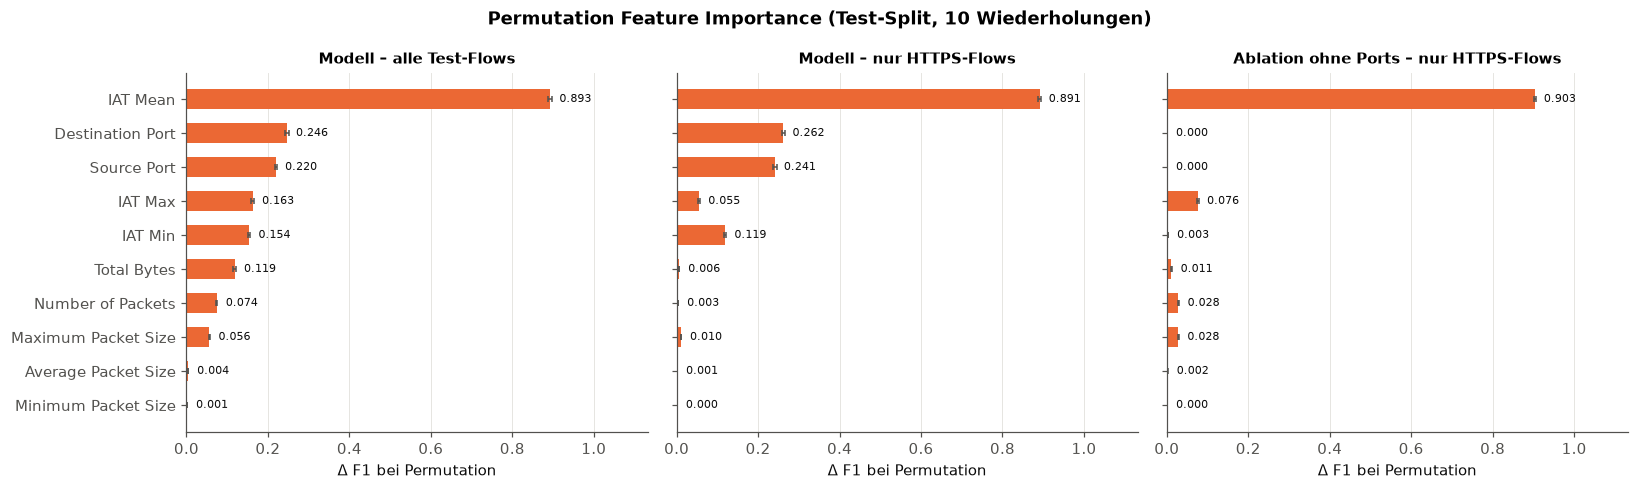

In [31]:
order = importance["Modell – alle Test-Flows"]["Δ F1"].sort_values().index  # wichtigstes Feature oben
panels = list(importance.items())
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
lim = max(imp["Δ F1"].max() + imp["Δ F1 std"].max() for _, imp in panels) * 1.25
for ax, (title, imp) in zip(axes, panels):
    imp = imp.loc[order]
    ax.barh(imp.index, imp["Δ F1"].clip(lower=0), xerr=imp["Δ F1 std"], color=C_MAL, height=0.6,
            error_kw=dict(ecolor=INK_MUTED, elinewidth=1, capsize=2))
    for yy, v in enumerate(imp["Δ F1"]):
        ax.text(max(v, 0) + lim * 0.02, yy, f"{v:.3f}", va="center", fontsize=7, color=INK)
    ax.set_xlim(0, lim)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Δ F1 bei Permutation")
    ax.set_title(title, fontsize=10)
fig.suptitle(f"Permutation Feature Importance (Test-Split, {N_REPEATS} Wiederholungen)", fontweight="bold")
plt.tight_layout()
plt.show()

Ergänzend eine gradientenbasierte Sicht: **Gradient × Input** misst lokal pro Flow, wie stark der Modell-Output auf ein
Feature reagiert, gewichtet mit dessen Wert. Gezeigt wird der mittlere Betrag getrennt nach wahrer Klasse (Modell mit Ports).

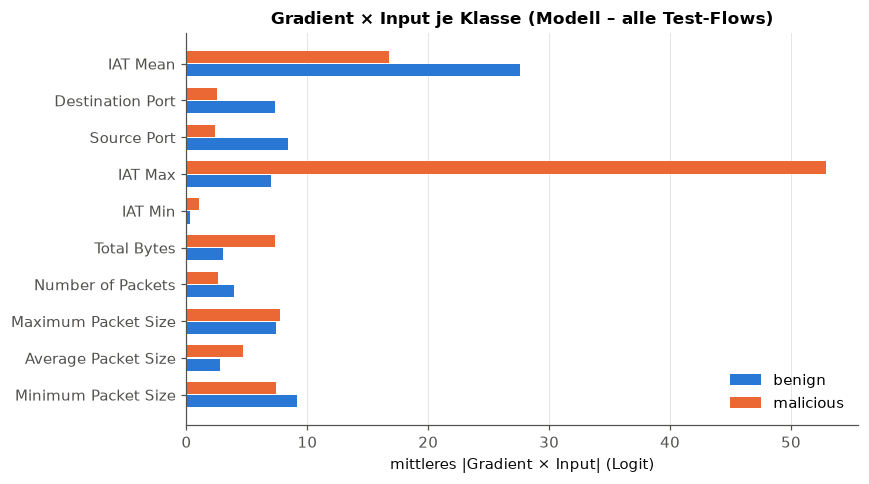

In [32]:
Xg = X_test.clone().requires_grad_(True)
model(Xg).sum().backward()
attr = (Xg.grad * X_test).abs().numpy()
gxi = pd.DataFrame({label: attr[y_true == cls].mean(axis=0) for label, cls in [("benign", 0), ("malicious", 1)]},
                   index=FEATURE_COLUMNS).loc[order]

fig, ax = plt.subplots(figsize=(8, 4.5))
ypos = np.arange(len(gxi))
for k, (label, color) in enumerate(CLASS_COLORS.items()):
    ax.barh(ypos + (k - 0.5) * 0.36, gxi[label], height=0.33, color=color, label=label)
ax.set_yticks(ypos, gxi.index)
ax.grid(axis="y", visible=False)
ax.set_xlabel("mittleres |Gradient × Input| (Logit)")
ax.set_title("Gradient × Input je Klasse (Modell – alle Test-Flows)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 10. Fehleranalyse

In [33]:
err = test_df.assign(score=scores, pred=y_pred)
err["Fall"] = np.select(
    [(err.is_mal == 1) & (err.pred == 1), (err.is_mal == 0) & (err.pred == 1),
     (err.is_mal == 1) & (err.pred == 0), (err.is_mal == 0) & (err.pred == 0)],
    ["TP", "FP", "FN", "TN"], default="?")
cols = ["Number of Packets", "Average Packet Size", "Total Bytes", "IAT Mean"]
display(err.groupby("Fall")[cols + ["score"]].median().assign(Flows=err["Fall"].value_counts()))

print("False Positives nach Dienstport:")
fp_ports = np.minimum(err.loc[err.Fall == "FP", "Source Port"], err.loc[err.Fall == "FP", "Destination Port"]).value_counts().head(10)
print(fp_ports.to_dict())
print("\nFalse Negatives – Paketanzahl:")
print(err.loc[err.Fall == "FN", "Number of Packets"].value_counts().head(10).to_dict())
print("\nFalse Negatives – Top-Angreifer-IPs:")
print(err.loc[err.Fall == "FN", "peer_ip"].value_counts().head(10).to_dict())

,Number of Packets,Average Packet Size,Total Bytes,IAT Mean,score,Flows
Fall,,,,,,
FN,10.0000,345.2000,"3,452.0000",7.3472,0.2939,1
FP,13.0000,149.7647,"2,523.0000",2.8952,0.8909,73
TN,9.0000,218.9167,"2,627.0000",0.1111,0.0000,96983
TP,17.0000,206.3571,"3,874.0000",4.0143,0.9998,6509


False Positives nach Dienstport:
{22: 42, 80: 12, 993: 6, 25: 6, 443: 4, 6443: 2, 465: 1}

False Negatives – Paketanzahl:
{10: 1}

False Negatives – Top-Angreifer-IPs:
{'217.254.83.129': 1}


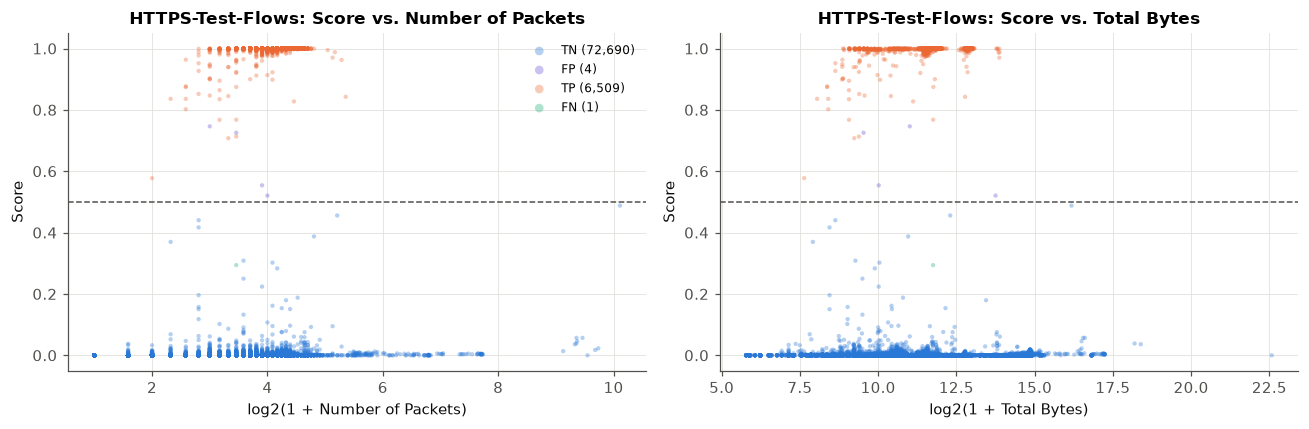

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
svc_err = err[err["is_svc"]]
for ax, col in zip(axes, ["Number of Packets", "Total Bytes"]):
    for case, color in [("TN", C_BENIGN), ("FP", "#6250d6"), ("TP", C_MAL), ("FN", C_ALT)]:
        v = svc_err.loc[svc_err["Fall"] == case, col]
        if len(v):
            ax.scatter(np.log2(1 + v), svc_err.loc[v.index, "score"], s=8, alpha=0.35, color=color, label=f"{case} ({len(v):,})", edgecolors="none")
    ax.set_xlabel(f"log2(1 + {col})")
    ax.set_ylabel("Score")
    ax.axhline(CUTOFF, color=INK_MUTED, linestyle="--", linewidth=1)
    ax.set_title(f"{SVC}-Test-Flows: Score vs. {col}")
axes[0].legend(markerscale=2, fontsize=8)
plt.tight_layout()
plt.show()

## Fazit

_wird nach Ausführung ergänzt_